# Gradient Boosting

**Objective:** Learn gradient boosting with simple, step-by-step examples.

## Gradient boosting intuition

Gradient boosting builds an additive model in stages. Each new tree improves the current ensemble by following the negative gradient of the chosen loss. For squared-error regression, this is closely related to fitting residuals, but the gradient view generalizes to other losses.

## How It Works
Gradient boosting builds small models one after another. Each new model focuses on reducing previous errors.

### Learning rate and number of trees

The learning rate shrinks each tree's contribution. A smaller rate often needs more trees. The number of estimators controls how many boosting stages are added. Use validation or early stopping to avoid adding trees after generalization stops improving.

## 1. Import Libraries
We start with the standard tools used in many scikit-learn examples.

### Tree depth and regularization

Shallow trees make simple corrections; deeper trees capture more interactions but can overfit. Subsampling and other constraints can regularize the ensemble. Tune these settings together.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

## Key terms

- **Additive model:** final prediction is the sum of many learner contributions.
- **Negative gradient:** direction that reduces loss locally.
- **Learning rate:** multiplier controlling each learner's contribution.
- **Early stopping:** stop adding learners when validation performance no longer improves.

## 2. Load the Dataset
The CSV file is stored inside this topic folder so the notebook is self-contained.

In [2]:
data = pd.read_csv('datasets/breast_cancer.csv')
data.head()

,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,diagnosis
0,12.6704,10.8800,85.5063,619.3016,0.0607,0.0279,benign
1,12.2812,13.0513,74.7648,296.4521,0.1032,0.1111,benign
2,12.1453,17.3817,81.5451,295.3274,0.0955,0.0416,benign
3,13.9326,13.8502,72.4119,327.4327,0.1083,0.0738,benign
4,11.0577,12.9436,82.4523,515.7799,0.0962,0.0972,benign


## 3. Explore the Data
Always inspect shape, columns, missing values, and basic statistics before modeling.

In [3]:
print(data.shape)
print(data.info())
data.describe()

(280, 7)
<class 'pandas.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   mean_radius       280 non-null    float64
 1   mean_texture      280 non-null    float64
 2   mean_perimeter    280 non-null    float64
 3   mean_area         280 non-null    float64
 4   mean_smoothness   280 non-null    float64
 5   mean_compactness  280 non-null    float64
 6   diagnosis         280 non-null    str    
dtypes: float64(6), str(1)
memory usage: 15.4 KB
None


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness
count,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000
mean,14.883669,17.288689,97.384052,701.029588,0.099514,0.118556
std,3.844473,4.652241,26.236474,309.942954,0.017472,0.056614
min,5.478000,5.981500,43.069700,-11.654000,0.053900,-0.022700
25%,11.862650,13.644550,76.364850,443.495625,0.086825,0.079875
50%,14.939150,16.781500,98.055100,702.104300,0.100700,0.116500
75%,17.953100,21.193350,119.719425,950.441300,0.111550,0.163450
max,24.993500,27.929500,160.799400,1455.658000,0.145800,0.242400


In [4]:
data.isna().sum()

mean_radius         0
mean_texture        0
mean_perimeter      0
mean_area           0
mean_smoothness     0
mean_compactness    0
diagnosis           0
dtype: int64

## 4. Prepare Features and Target
`X` contains the input columns. `y` contains the answer we want to predict.

In [5]:
X = data.drop(columns=['diagnosis'])
y = data['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)

(224, 6) (56, 6)


## 5. Train the Model
Classification models learn to predict categories.

In [6]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import GradientBoostingClassifier

model = GradientBoostingClassifier(random_state=RANDOM_STATE)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

## 6. Predict and Evaluate
Accuracy is easy to understand, but the classification report shows more detail.

Accuracy: 0.982
              precision    recall  f1-score   support

      benign       1.00      0.96      0.98        28
   malignant       0.97      1.00      0.98        28

    accuracy                           0.98        56
   macro avg       0.98      0.98      0.98        56
weighted avg       0.98      0.98      0.98        56



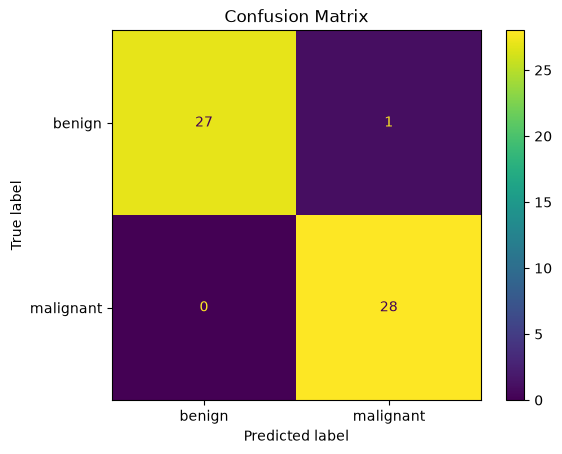

In [7]:
predictions = model.predict(X_test)

print('Accuracy:', round(accuracy_score(y_test, predictions), 3))
print(classification_report(y_test, predictions))

ConfusionMatrixDisplay.from_predictions(y_test, predictions)
plt.title('Confusion Matrix')
plt.show()

## Try This Yourself
- Change the selected feature columns.
- Try a different `test_size`.
- Inspect a few incorrect predictions.